# Uncapacitated facility location

The <code>mip</code> package and its underlying solvers are able to solve not only linear programs, but also integer programs and *mixed integer programs*. Here we implement and solve the integer program for uncapacitated facility location:

$$
\begin{array}{lll}
\min & \sum_{i\in\mathcal F}y_if_i
+\sum_{i\in\mathcal F,j\in\mathcal D}x_{ij}c_{ij},
& y\in\mathbb R^{\mathcal F},\, x\in\mathbb R^{\mathcal F\times\mathcal D}\\
\textrm{subject to} & x_{ij}\leq y_i & \textrm{for all }i\in\mathcal F,\,j\in\mathcal D\\
& \sum_{i\in\mathcal F}x_{ij}\geq 1 & \textrm{for all }j\in\mathcal D\\
& x_{ij}\in\{0,1\},\,y_i\in\{0,1\} & \textrm{for all }i\in\mathcal F,\,j\in\mathcal D
\end{array}
$$


We use the <code>mip</code> package. Documentation can be found [here.](https://python-mip.readthedocs.io/en/latest/)
If you are working in Google Colab, use the next cell exactly as it is. If you are working on your own computer and don't have mip already installed, you may need to install it by hand, depending on your OS.

We need some packages.

In [1]:
try: 
    import mip  ## Library for linear programs and MIPs
except:
    !pip install mip
    import mip
import numpy as np ## Standard library for scientific computing
import random
import math
import matplotlib.pyplot as plt
### We use the fivethirtyeight style to make the plots look a bit prettier
### could also be omitted
plt.style.use('fivethirtyeight')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 191.3/191.3 MB 39.6 MB/s eta 0:00:00m eta 0:00:010:0108


## Generating a random instance

As always, we need an example instance, which we generate randomly. We place facilities and customers randomly in the plane. We then use the standard Euclidean distance in the plane as the connection/operating costs. We set the construction costs to $1$ everywhere.

In [2]:
def rnd_instance(num_facilities=10,num_customers=30):
    facilities=[(random.random(),random.random()) for _ in range(num_facilities)]
    customers=[(random.random(),random.random()) for _ in range(num_customers)]
    opening_costs=[1]*num_facilities  ## for simplicity, all opening costs are 1
    return facilities,customers,opening_costs

def distance(facility,customer):
    px,py=facility
    qx,qy=customer
    return math.sqrt((px-qx)**2+(py-qy)**2)

facilities,customers,opening_costs=rnd_instance()

A bit of visualization code. This is a little more complicated, but not necessary to understand the MIP or its solution. I.e., just ignore it.

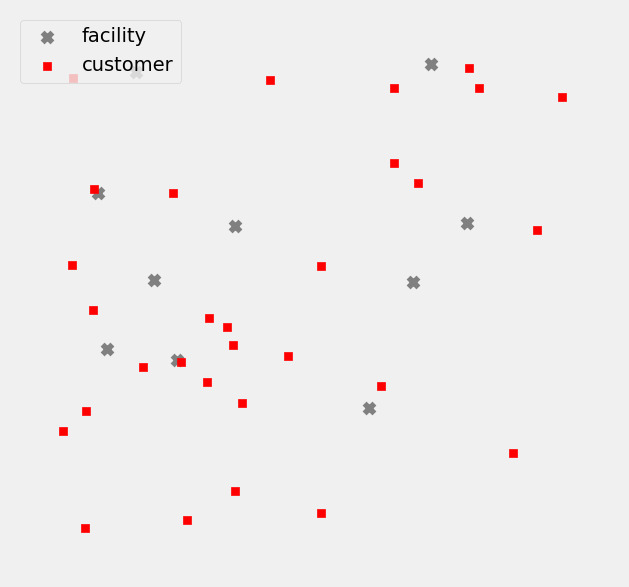

In [3]:
def show(facilities,customers,x=None,y=None):
    plt.figure(figsize=(7,7))
    BB=np.array(facilities)
    CC=np.array(customers)
    if y is None:
        closed=BB
    else:
        opened=np.array([F for i,F in enumerate(facilities) if y[i].x==1])
        closed=np.array([F for i,F in enumerate(facilities) if y[i].x==0])
        plt.scatter(opened[:,0],opened[:,1],color='blue',s=100,marker='o',label="open")
    plt.scatter(closed[:,0],closed[:,1],color='gray',s=50,marker='x',label="facility")
    plt.scatter(CC[:,0],CC[:,1],color='red',marker='s',label="customer")
    if x is not None:
        for i in range(len(facilities)):
            for j in range(len(customers)):
                if x[i][j].x>0.0001:
                    plt.plot([BB[i,0],CC[j,0]],[BB[i,1],CC[j,1]],'k',zorder=-1,alpha=0.5,linewidth=2)
    plt.xlim(-0.1,1.1)
    plt.ylim(-0.1,1.1)
    plt.xticks([])
    plt.yticks([])
    plt.legend(loc="upper left")
    plt.show()

show(facilities,customers)

## The MIP

We start by instantiating the <code>Model</code>.

In [4]:
model=mip.Model()
num_customers=len(customers)
num_facilities=len(facilities)

Binary variables are created by setting <code>var_type=mip.BINARY</code>. For integer variables, one would set <code>var_type=mip.INTEGER</code> here.

$y_i\in\{0,1\}$

In [5]:
y=[model.add_var(var_type=mip.BINARY) for _ in range(num_facilities)]

Next we create the connection variables.

$x_{ij}\in\{0,1\}$

In [6]:
x=[[model.add_var(var_type=mip.BINARY) for _ in range(num_customers)] for _ in range(num_facilities)]

The objective function. As connection/operating costs, we take the distance in the plane.

$\min\sum_{i}y_if_i+\sum_{ij}x_{ij}c_{ij}$

In [7]:
model.objective=mip.minimize(mip.xsum(y[i]*opening_costs[i] for i in range(num_facilities)) + \
                         mip.xsum(x[i][j]*distance(facilities[i],customers[j]) for i in range(num_facilities) for j in range(num_customers)))

What is the backslash <code>\\</code> doing at the end of the first line? Python defines code blocks through indentation and expects one command per line. Sometimes, like here with the objective function, a command is very long & for reasons of clarity one would like to split the command over several lines. The backslash at the end of the line signals to Python that the command is continued on the next line. This is also possible across multiple lines.

and therefore reacts a bit irritably if you simply interrupt a line that is too long and continue it on the next line.

The indicator variable constraints -- no connection to an unopened facility:

$x_{ij}\leq y_i$

In [8]:
for i in range(num_facilities):
    for j in range(num_customers):
        model+=x[i][j]<=y[i]

Every customer must be connected:

$\sum_{i}x_{ij}\geq 1$

In [9]:
for j in range(num_customers):
    model+=mip.xsum(x[i][j] for i in range(num_facilities)) >= 1

We start the optimization and display the solution right away:


▶ Problem loading

  |Rows| = 330   |Cols| = 310   |NZ| = 900
  Variables: 310 binary, 0 integer, 0 continuous

  Coefficient ranges:
    Matrix  ∈ [       1,      1]   κ ≈     1
    Cost    ∈ [0.010439, 1.1962]   κ ≈ 114.6
    Bounds  ∈ [       1,      1]   κ ≈     1
    RHS     ∈ [       1,      1]   κ ≈     1

✔ Problem loaded — 330 rows, 310 cols, 900 NZ, 310 integer

▶ Non-default parameters

  allowableGap  1e-12 → 1e-10
  ratioGap  0 → 0.0001
  lpTimeFreq  5 → 0

▶ Root LP relaxation

  Bound tightening: 0 bounds tightened (0 fixed) in 0.000 s.
  Clique strengthening: no changes (0.00s)
  Coefficient strengthening: no changes (0.00s)
  Row reductions: no changes (0.00s)
  LP auto: recommended dual_pesteep_psineg1_pertv61

▶ Preprocessing


  Processed model: 330 rows, 310 cols, 900 NZ
                   310 integer (310 binary)

  Conflict graph: built in 0.00s, density 0.317%
  Clique strengthening: extended 0, dominated 0

✔ Preprocessing complete — Time: 0.003s

▶ Root node 

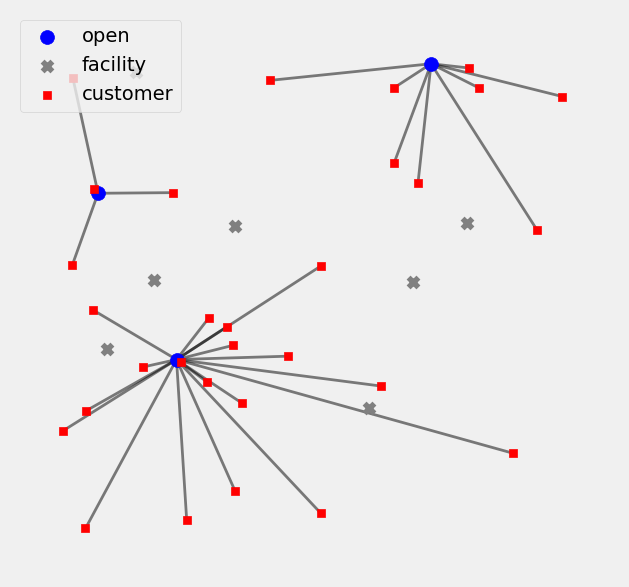

In [10]:
model.optimize()

show(facilities,customers,x,y)